In [1]:
import os
import os.path as op

import matplotlib.pyplot as plt

import hnn_core
from hnn_core.params import _short_name

from hnn_core import new_calcium_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'

# The number of cores may need modifying depending on your current machine.
n_procs = 10

In [2]:
from urllib.request import urlretrieve

exp_dpl = read_dipole('/Users/katharinaduecker/Documents/projects_brown/hnn-data/MEG_detection_data/S1_SupraT.txt')

## Handtune

In [3]:

prox1_weights_ampa = {'L2_basket': 0.009355766425012867*0.1,
                        'L2_pyramidal': 0.017821964058181386*0.4,
                        'L5_basket': 0.06360458875185422,
                        'L5_pyramidal': 0.19529920430756656}
prox1_weights_nmda = {'L2_basket': 0.0019710468589739668*0.1,
                        'L2_pyramidal': 0.005363307709092387*0.3,
                        'L5_basket': 0.004440122026440295,
                        'L5_pyramidal': 0.11613875475625732*0.2}

dist_weights_ampa = {'L2_basket': 0.0034061998909488485*0.1,
                    'L2_pyramidal': 0.04571263358904524*2,
                    'L5_pyramidal': 0.03070737911180561*2}
dist_weights_nmda = {'L2_basket': 0.0032451182438157145,
                    'L2_pyramidal': 0.023128505130650276,
                    'L5_pyramidal': 0.23013679176569424}

prox2_weights_ampa = {'L2_basket': 0.0068621596378251855,
                        'L2_pyramidal': 0.03098179455638236,
                        'L5_basket': 0.0028128946269181136,
                        'L5_pyramidal': 0.6487065801685004}
prox2_weights_nmda = {'L2_basket': 0.009409301539150934,
                    'L2_pyramidal': 0.12711473194831402,
                    'L5_basket': 0.00028935388454280175,
                    'L5_pyramidal': 0.3419028116089666}



Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...


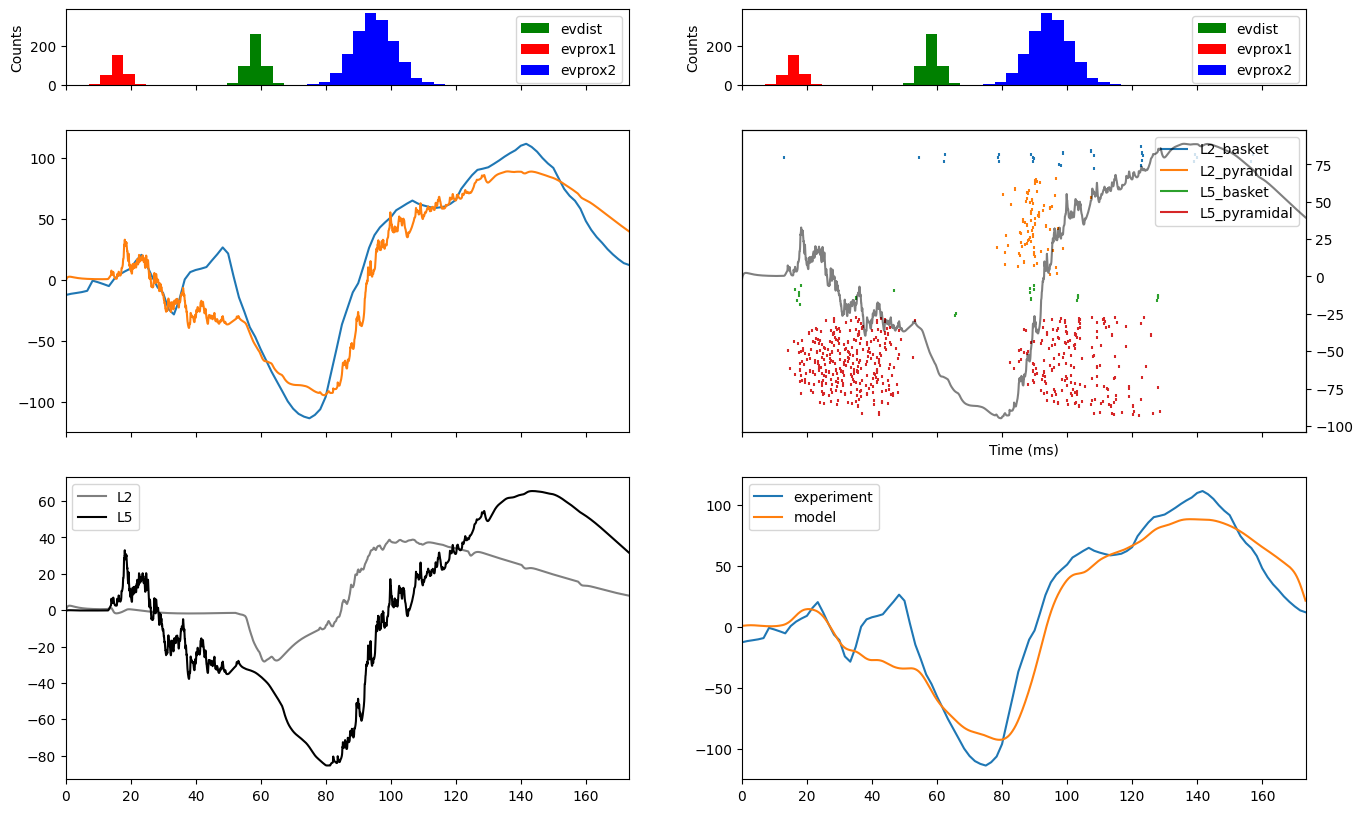

In [4]:
tstop = exp_dpl.times[-1]
scale_factor = 1000
smooth_window_len = 10

net_init = new_calcium_model()
# net_init.set_cell_positions(inplane_distance=30.)

# depths = list(list(range(-100,2400,200)))
# electrode_pos = [(135, 135, dep) for dep in depths]

# net_init.add_electrode_array('probe1', electrode_pos)

synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
net_init.add_evoked_drive('evprox1',
                        mu=16.,
                        sigma=2.3,
                        numspikes=1,
                        location='proximal',
                        weights_ampa=prox1_weights_ampa,
                        weights_nmda=prox1_weights_nmda,
                        synaptic_delays=synaptic_delays_p, event_seed=544)

# Distal
synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

net_init.add_evoked_drive('evdist',
                        mu=58.5,
                        sigma=2.5,
                        numspikes=2,
                        location='distal',
                        weights_ampa=dist_weights_ampa,
                        weights_nmda=dist_weights_nmda,
                        synaptic_delays=synaptic_delays_d, event_seed=544)

net_init.add_evoked_drive('evprox2',
                    mu=95,
                    sigma=6,
                    numspikes=6,
                    location='proximal',
                    weights_ampa=prox2_weights_ampa,
                    weights_nmda=prox2_weights_nmda,
                    synaptic_delays=synaptic_delays_p, event_seed=544)
init_dpl = simulate_dipole(net_init, tstop=tstop, n_trials=1,bsl_cor='calcium', record_vsec='all', record_isec='all')[0]

init_dpl.scale(scale_factor)#.smooth(smooth_window_len)


fig, ax = plt.subplots(3,2,figsize=(16,10), height_ratios=[0.25,1,1], sharex=True)

net_init.cell_response.plot_spikes_hist(ax=ax[0,0], spike_types=['evprox1', 'evdist', 'evprox2'], show=False)
net_init.cell_response.plot_spikes_hist(ax=ax[0,1], spike_types=['evprox1', 'evdist', 'evprox2'], show=False)


ax[1,0].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment')

ax[1,0].plot(init_dpl.times,init_dpl.data['agg'], label='model')

net_init.cell_response.plot_spikes_raster(ax=ax[1,1], show=False)
ax2 = ax[1,1].twinx()
ax2.plot(init_dpl.times,init_dpl.data['agg'],color='k', alpha=0.5)

ax[2,0].plot(init_dpl.times,init_dpl.data['L2'], label='L2', color='k', alpha=0.5)
ax[2,0].plot(init_dpl.times,init_dpl.data['L5'], label='L5', color='k')
ax[2,0].legend()

ax[2,1].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment')

smooth_dpl = init_dpl.smooth(smooth_window_len)
ax[2,1].plot(smooth_dpl.times,smooth_dpl.data['agg'], label='model')
ax[2,1].legend()


fig.savefig(os.path.join(pathfig,'initial_dpl.png'))

In [5]:
from hnn_core.dipole import _rmse

_rmse(smooth_dpl, exp_dpl,tstart=0,tstop=1000)

np.float64(20.679470604928703)

In [ ]:
# fig, ax = plt.subplots(1,3,figsize=(19,4),sharex=True)

# net_init.cell_response.plot_spikes_raster(ax=ax[0], show=False)
# ax2 = ax[0].twinx()
# ax2.plot(init_dpl.times,init_dpl.data['agg'],color='k', alpha=0.5)

# net_init.rec_arrays['probe1'][0].plot_lfp(ax=ax[1], show=False)
# net_init.rec_arrays['probe1'][0].plot_csd(ax=ax[2], show=False, vmin=-0.01, vmax=0.01)

# ax[0].set_title('Raster plot')
# ax[1].set_title('LFP')
# ax[2].set_title('CSD')
# fig.tight_layout()
# fig.savefig(os.path.join(pathfig,'accidental_ING.png'))


In [ ]:
net_init.cell_response.mean_rates(tstart = 0, tstop=100, gid_ranges=net_init.gid_ranges, mean_type='all')

In [ ]:
cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']
dt = np.diff(net_init.cell_response.times)[0]
window_samples = smooth_window_len/dt
num_win = int(net_init.cell_response.times.shape[0] - window_samples)

cell_rates = dict()

spike_gids = np.array(net_init.cell_response.spike_gids[0])

for cell_type in cell_types:
    cell_type_gids = np.array(net_init.gid_ranges[cell_type])
    n_trials, n_cells = len(net_init.cell_response.spike_times), len(cell_type_gids)
    gid_spike_rate = np.zeros((n_cells, num_win))
    cell_rates[cell_type] = gid_spike_rate

    for i,cid in enumerate(cell_type_gids):
        
        spike_times = np.array(net_init.cell_response.spike_times[0])[np.isin(spike_gids, cid)]


        for n in range(num_win):

            time_id = np.where((spike_times >= net_init.cell_response.times[n]) & (spike_times < net_init.cell_response.times[n]+smooth_window_len))[0]
            spike_rate = len(time_id)/smooth_window_len*1000
            cell_rates[cell_type][i, n] = spike_rate

In [ ]:
fig, ax = plt.subplots(2,2, figsize=(12,6), sharey=True, sharex=True)
ax = ax.ravel()
for i, cell_type in enumerate(cell_types):

    ax[i].plot(net_init.cell_response.times[:-int(window_samples)], cell_rates[cell_type].mean(axis=0))
    ax[i].errorbar(net_init.cell_response.times[:-int(window_samples)], cell_rates[cell_type].mean(axis=0), yerr=cell_rates[cell_type].std(axis=0), alpha=0.01, color='tab:blue')
    ax[i].set_title(cell_type)

ax[0].set_ylabel('spike rates')
ax[2].set_ylabel('spike rates')
ax[2].set_xlabel('time (ms)')
ax[3].set_xlabel('time (ms)')

fig.tight_layout()

In [ ]:
net_init = jones_2009_model()

net_init.add_evoked_drive('evprox1',
                          mu=21, sigma=3.,
                          numspikes=1,
                          location='proximal',
                          weights_ampa=weights_ampa_p1,
                          weights_nmda=weights_nmda_p1,
                          synaptic_delays=synaptic_delays_p, event_seed=544)


net_init.add_evoked_drive('evdist1',
                          mu=58.6539,
                          sigma=3,
                          numspikes=1,
                          location='distal',
                          weights_ampa=weights_ampa_d1,
                          weights_nmda=weights_nmda_d1,
                          synaptic_delays=synaptic_delays_d1)


net_init.add_evoked_drive('evprox2',
                          mu=95,
                          sigma=10,
                          numspikes=3,
                          location='proximal',
                          weights_ampa=weights_ampa_p2,
                          weights_nmda=weights_nmda_p2,
                          synaptic_delays=synaptic_delays_p)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    init_dpl = simulate_dipole(net_init, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]

init_dpl.scale(scale_factor)#.smooth(smooth_window_len)


fig, ax = plt.subplots(3,2,figsize=(16,10), height_ratios=[0.25,1,1], sharex=True)

net_init.cell_response.plot_spikes_hist(ax=ax[0,0], spike_types=['evprox1', 'evdist1', 'evprox2'], show=False)
net_init.cell_response.plot_spikes_hist(ax=ax[0,1], spike_types=['evprox1', 'evdist1', 'evprox2'], show=False)


ax[1,0].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment')

ax[1,0].plot(init_dpl.times,init_dpl.data['agg'], label='model')

net_init.cell_response.plot_spikes_raster(ax=ax[1,1], show=False)
ax2 = ax[1,1].twinx()
ax2.plot(init_dpl.times,init_dpl.data['agg'],color='k', alpha=0.5)

ax[2,0].plot(init_dpl.times,init_dpl.data['L2'], label='L2', color='k', alpha=0.5)
ax[2,0].plot(init_dpl.times,init_dpl.data['L5'], label='L5', color='k')
ax[2,0].legend()

ax[2,1].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment')

smooth_dpl = init_dpl.smooth(smooth_window_len)
ax[2,1].plot(smooth_dpl.times,smooth_dpl.data['agg'], label='model')
ax[2,1].legend()


fig.savefig(os.path.join(pathfig,'initial_dpl_jones.png'))

## Optimize

### Strength of drives

In [ ]:
def set_params(net, params):

    # Proximal 1
    synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
    
    weights_ampa_p1 = {'L2_basket':
                       params['evprox1_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evprox1_ampa_L2_pyramidal'],
                       'L5_basket':
                       params['evprox1_ampa_L5_basket'],
                       'L5_pyramidal':
                       params['evprox1_ampa_L5_pyramidal']}
    weights_nmda_p1 = {'L2_basket':
                       params['evprox1_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evprox1_nmda_L2_pyramidal'],
                       'L5_basket':
                       params['evprox1_nmda_L5_basket'],
                       'L5_pyramidal':
                       params['evprox1_nmda_L5_pyramidal']}

    
    net.add_evoked_drive('evprox1',
                         mu=17.5,
                         sigma=2.3,
                         numspikes=1,
                         location='proximal',
                         weights_ampa=weights_ampa_p1,
                         weights_nmda=weights_nmda_p1,
                         synaptic_delays=synaptic_delays_p, event_seed=544)

    # Distal
    synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}
    
    weights_ampa_d = {'L2_basket':
                       params['evdist_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evdist_ampa_L2_pyramidal'],
                       'L5_pyramidal':
                       params['evdist_ampa_L5_pyramidal']}
    weights_nmda_d = {'L2_basket':
                       params['evdist_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evdist_nmda_L2_pyramidal'],
                       'L5_pyramidal':
                       params['evdist_nmda_L5_pyramidal']}
    

    net.add_evoked_drive('evdist',
                         mu=60.5,
                         sigma=2.5,
                         numspikes=2,
                         location='distal',
                         weights_ampa=weights_ampa_d,
                         weights_nmda=weights_nmda_d,
                         synaptic_delays=synaptic_delays_d, event_seed=544)


    weights_ampa_p2 = {'L2_basket':
                       params['evprox2_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evprox2_ampa_L2_pyramidal'],
                       'L5_basket':
                       params['evprox2_ampa_L5_basket'],
                       'L5_pyramidal':
                       params['evprox2_ampa_L5_pyramidal']}
    weights_nmda_p2 = {'L2_basket':
                       params['evprox2_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evprox2_nmda_L2_pyramidal'],
                       'L5_basket':
                       params['evprox2_nmda_L5_basket'],
                       'L5_pyramidal':
                       params['evprox2_nmda_L5_pyramidal']}
    
    net.add_evoked_drive('evprox2',
                        mu=95,
                        sigma=6,
                        numspikes=6,
                        location='proximal',
                        weights_ampa=weights_ampa_p2,
                        weights_nmda=weights_nmda_p2,
                        synaptic_delays=synaptic_delays_p, event_seed=544)
    
    delay = net.delay

# constrain such that L5 is driven more than L2
constraints = dict({'evprox1_ampa_L2_basket': (0.00005, 0.009),
                'evprox1_ampa_L2_pyramidal': (0.005, 0.2),
                'evprox1_ampa_L5_basket': (0.01, 0.1),
                'evprox1_ampa_L5_pyramidal': (0.01, .4),

                'evprox1_nmda_L2_basket': (0.00005, 0.0009),
                'evprox1_nmda_L2_pyramidal': (0.0005, 0.004),
                'evprox1_nmda_L5_basket': (0.0001, 0.01),
                'evprox1_nmda_L5_pyramidal': (0.005, 0.4),

                'evdist_ampa_L2_basket': (0.0001, 0.005),
                'evdist_ampa_L2_pyramidal': (0.01, 0.1),
                'evdist_ampa_L5_pyramidal': (0.01, 0.3),
                'evdist_nmda_L2_basket': (0.0001, 0.009),
                'evdist_nmda_L2_pyramidal': (0.001, .5),
                'evdist_nmda_L5_pyramidal': (0.001, .5),

                'evprox2_ampa_L2_basket': (1e-6, 1e-2),
                'evprox2_ampa_L2_pyramidal': (0.01, .2),
                'evprox2_ampa_L5_basket': (1e-6, 1e-2),
                'evprox2_ampa_L5_pyramidal': (0.1, 1.),
                'evprox2_nmda_L2_basket': (1e-6, 1e-2),
                'evprox2_nmda_L2_pyramidal': (0.01, .2),
                'evprox2_nmda_L5_basket': (1e-7, 1e-3),
                'evprox2_nmda_L5_pyramidal': (0.1, 1.5)})
    


In [ ]:
net = new_calcium_model()
optim = Optimizer(net, tstop=tstop, constraints=constraints,
                  set_params=set_params, solver='bayesian', obj_fun='dipole_rmse', max_iter=400)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    optim.fit(target=exp_dpl, scale_factor=scale_factor,
              smooth_window_len=smooth_window_len,bsl_cor='calcium')
    
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    opt_dpl = simulate_dipole(optim.net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
opt_dpl.scale(scale_factor)
opt_dpl.smooth(smooth_window_len)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].legend(['experimental', 'initial', 'optimized'])
optim.net_.cell_response.plot_spikes_hist(ax=axes[1])

fig1 = optim.plot_convergence()

In [ ]:
init_rmse = _rmse(init_dpl, exp_dpl, tstart=0, tstop=1000)
opt_rmse = _rmse(opt_dpl, exp_dpl, tstart=0, tstop=1000)

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(12, 3), sharex=True)

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
axes[0].text(150,120, f'init RMSE: {init_rmse:.2f}', fontsize=12, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].text(150,100, f'opt RMSE: {opt_rmse:.2f}', fontsize=12, color='tab:green')

optim.net_.cell_response.plot_spikes_raster(ax=axes[1], show=False)
ax2 = axes[1].twinx()
ax2.plot(opt_dpl.times,opt_dpl.data['agg'],color='k', alpha=0.5)

In [ ]:
optim.net_.external_drives['evprox2']['weights_nmda']

In [ ]:
prox1_weights_ampa = {'L2_basket': 0.009355766425012867*0.1,
                        'L2_pyramidal': 0.017821964058181386*0.75,
                        'L5_basket': 0.06360458875185422*1.5,
                        'L5_pyramidal': 0.19529920430756656}
prox1_weights_nmda = {'L2_basket': 0.0019710468589739668*0.1,
                        'L2_pyramidal': 0.005363307709092387*0.75,
                        'L5_basket': 0.004440122026440295,
                        'L5_pyramidal': 0.11613875475625732*0.2}

dist_weights_ampa = {'L2_basket': 0.0034061998909488485*0.1,
                    'L2_pyramidal': 0.04571263358904524*2,
                    'L5_pyramidal': 0.03070737911180561*2}
dist_weights_nmda = {'L2_basket': 0.0032451182438157145,
                    'L2_pyramidal': 0.023128505130650276,
                    'L5_pyramidal': 0.23013679176569424}

prox2_weights_ampa = {'L2_basket': 0.0068621596378251855,
                        'L2_pyramidal': 0.03098179455638236,
                        'L5_basket': 0.0028128946269181136,
                        'L5_pyramidal': 0.6487065801685004}
prox2_weights_nmda = {'L2_basket': 0.009409301539150934,
                    'L2_pyramidal': 0.12711473194831402,
                    'L5_basket': 0.00028935388454280175,
                    'L5_pyramidal': 0.3419028116089666}

In [ ]:
net = new_calcium_model()  

# proximal 1
synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
net.add_evoked_drive('evprox1',
                        mu=16.,
                        sigma=2.3,
                        numspikes=1,
                        location='proximal',
                        weights_ampa=prox1_weights_ampa,
                        weights_nmda=prox1_weights_nmda,
                        synaptic_delays=synaptic_delays_p, event_seed=544)

# Distal
synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

net.add_evoked_drive('evdist',
                        mu=58.5,
                        sigma=2.5,
                        numspikes=2,
                        location='distal',
                        weights_ampa=dist_weights_ampa,
                        weights_nmda=dist_weights_nmda,
                        synaptic_delays=synaptic_delays_d, event_seed=544)

net.add_evoked_drive('evprox2',
                    mu=95,
                    sigma=6,
                    numspikes=6,
                    location='proximal',
                    weights_ampa=prox2_weights_ampa,
                    weights_nmda=prox2_weights_nmda,
                    synaptic_delays=synaptic_delays_p, event_seed=544)


hand_dpl = simulate_dipole(net, tstop=tstop, n_trials=1,bsl_cor='calcium', record_vsec='all', record_isec='all')[0]

hand_dpl.scale(scale_factor).smooth(smooth_window_len)  

fig, axes = plt.subplots(1,2,figsize=(12, 3), sharex=True)

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
hand_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')

net.cell_response.plot_spikes_raster(ax=axes[1], show=False)
ax2 = axes[1].twinx()
ax2.plot(hand_dpl.times,hand_dpl.data['L5'],color='k', alpha=0.5)
ax2.plot(hand_dpl.times,hand_dpl.data['L2'],color='k', alpha=0.2)

In [ ]:
_rmse(opt_dpl, exp_dpl, tstart=0, tstop=1000)

In [ ]:
from hnn_core.dipole import _rmse

_rmse(hand_dpl, exp_dpl, tstart=0, tstop=1000)

### Timing of drives

In [ ]:
prox1_weights_ampa = optim.net_.external_drives['evprox1']['weights_ampa']
prox1_weights_nmda = optim.net_.external_drives['evprox1']['weights_nmda']

dist_weights_ampa = optim.net_.external_drives['evdist']['weights_ampa']
dist_weights_nmda = optim.net_.external_drives['evdist']['weights_nmda']

prox2_weights_ampa = optim.net_.external_drives['evprox2']['weights_ampa']
prox2_weights_nmda = optim.net_.external_drives['evprox2']['weights_nmda']

synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}

synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

def set_params_time(net, params):

    # Proximal 1
    
    net.add_evoked_drive('evprox1',
                         mu=params['evprox1_mu'],
                         sigma=params['evprox1_sigma'],
                         numspikes=1,
                         location='proximal',
                         weights_ampa=prox1_weights_ampa,
                         weights_nmda=prox1_weights_nmda,
                         synaptic_delays=synaptic_delays_p, event_seed=544)

    # Distal
    
    net.add_evoked_drive('evdist',
                         mu=params['evdist_mu'],
                         sigma=params['evdist_sigma'],
                         numspikes=int(params['evdist_num_spikes']),
                         location='distal',
                         weights_ampa=dist_weights_ampa,
                         weights_nmda=dist_weights_nmda,
                         synaptic_delays=synaptic_delays_d, event_seed=544)
    
    net.add_evoked_drive('evprox2',
                        mu=params['evprox2_mu'],
                        sigma=params['evprox2_sigma'],
                        numspikes=int(params['evprox2_num_spikes']),
                        location='proximal',
                        weights_ampa=prox2_weights_ampa,
                        weights_nmda=prox2_weights_nmda,
                        synaptic_delays=synaptic_delays_p, event_seed=544)
    
    delay = net.delay


constraints = dict({'evprox1_mu': (17, 18),
                'evprox1_sigma': (2.5, 4.5),

                'evdist_mu': (60, 62),
                'evdist_sigma': (2, 3),
                'evdist_num_spikes': (1, 2),

                'evprox2_mu': (94, 100),
                'evprox2_sigma': (8, 10),
                'evprox2_num_spikes': (1, 7)})

In [ ]:
net = new_calcium_model()
optim_time = Optimizer(net, tstop=tstop, constraints=constraints,
                  set_params=set_params_time, solver='bayesian', obj_fun='dipole_rmse', max_iter=200)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    optim_time.fit(target=exp_dpl, scale_factor=scale_factor,
              smooth_window_len=smooth_window_len,bsl_cor='calcium')
    
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    opt_dpl = simulate_dipole(optim_time.net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
opt_dpl.scale(scale_factor)
opt_dpl.smooth(smooth_window_len)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].legend(['experimental', 'initial', 'optimized'])
optim_time.net_.cell_response.plot_spikes_hist(ax=axes[1])

fig1 = optim_time.plot_convergence()

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(12, 3), sharex=True)

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')

optim_time.net_.cell_response.plot_spikes_raster(ax=axes[1], show=False)
ax2 = axes[1].twinx()
ax2.plot(opt_dpl.times,opt_dpl.data['agg'],color='k', alpha=0.5)

In [ ]:
prox1_mu = optim_time.net_.external_drives['evprox1']['dynamics']['mu'] 
prox1_sigma = optim_time.net_.external_drives['evprox1']['dynamics']['sigma']
prox1_num_spikes = optim_time.net_.external_drives['evprox1']['dynamics']['numspikes']
dist_mu = optim_time.net_.external_drives['evdist']['dynamics']['mu']
dist_sigma = optim_time.net_.external_drives['evdist']['dynamics']['sigma']         
dist_num_spikes = optim_time.net_.external_drives['evdist']['dynamics']['numspikes']
prox2_mu = optim_time.net_.external_drives['evprox2']['dynamics']['mu']
prox2_sigma = optim_time.net_.external_drives['evprox2']['dynamics']['sigma']
prox2_num_spikes = optim_time.net_.external_drives['evprox2']['dynamics']['numspikes']

In [ ]:
import pickle

with open('optim_time.pkl', 'wb') as file:
        pickle.dump(optim_time.net_, file)

with open('optim_drives.pkl', 'wb') as file:
        pickle.dump(optim.net_, file)

In [ ]:
from hnn_core.dipole import _rmse

_rmse(opt_dpl, exp_dpl, tstart=0, tstop=1000)

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(12, 3), sharex=True)

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')

optim_time.net_.cell_response.plot_spikes_raster(ax=axes[1], show=False)
ax2 = axes[1].twinx()
ax2.plot(opt_dpl.times,opt_dpl.data['agg'],color='k', alpha=0.5)